In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from config import PROCESSED
from utils import load_bg, load_stations, group_summary

pd.set_option("display.float_format", "{:,.2f}".format)

Block groups are split at the citywide median of tract income and garage share, with attached housing share as a supplementary split. Medians are reported because distances are skewed.

In [2]:
bg = load_bg()
print({k: round(v, 3) for k, v in bg.attrs["medians"].items()})
group_summary(bg, ["garage_grp", "income_grp"])

{'income': 57571.0, 'garage': 0.174, 'attached': 0.664}


n_blockgroups  walk_l2_m (median)  \
garage_grp   income_grp                                         
Few garages  Higher income            258            1,082.50   
             Lower income             358            1,853.00   
More garages Higher income            358            2,510.10   
             Lower income             255            2,672.40   

                            l2_ports_800 (median)  drive_dcfc_min (median)  \
garage_grp   income_grp                                                      
Few garages  Higher income                   0.00                     2.30   
             Lower income                    0.00                     4.10   
More garages Higher income                   0.00                     3.50   
             Lower income                    0.00                     3.90   

                            share with L2 port within 800 m  
garage_grp   income_grp                                      
Few garages  Higher income                             0.38  
             Lower income                              0.17  
More garages Higher income                             0.17  
             Lower income                              0.04

In [3]:
group_summary(bg, ["attached_grp", "income_grp"])

n_blockgroups  walk_l2_m (median)  \
attached_grp    income_grp                                         
Less attached   Higher income            369            1,339.20   
                Lower income             246            1,824.80   
Mostly attached Higher income            247            2,081.20   
                Lower income             367            2,320.30   

                               l2_ports_800 (median)  drive_dcfc_min (median)  \
attached_grp    income_grp                                                      
Less attached   Higher income                   0.00                     2.90   
                Lower income                    0.00                     4.00   
Mostly attached Higher income                   0.00                     2.80   
                Lower income                    0.00                     4.10   

                               share with L2 port within 800 m  
attached_grp    income_grp                                      
Less attached   Higher income                             0.35  
                Lower income                              0.25  
Mostly attached Higher income                             0.12  
                Lower income                              0.03

## Income gap among block groups with few garages

In [4]:
from scipy.stats import mannwhitneyu

few = bg[bg.garage_grp == "Few garages"].dropna(subset=["income_grp"])
rows = []
few = few.assign(any_port_800=(few.l2_ports_800 > 0).astype(int))
for col in ["walk_l2_m", "any_port_800", "drive_dcfc_min"]:
    lo = few.loc[few.income_grp == "Lower income", col]
    hi = few.loc[few.income_grp == "Higher income", col]
    p = mannwhitneyu(lo, hi).pvalue
    stat = "mean" if col == "any_port_800" else "median"
    lo_v, hi_v = getattr(lo, stat)(), getattr(hi, stat)()
    rows.append({"metric": f"{col} ({stat})", "lower income": round(lo_v, 3), "higher income": round(hi_v, 3),
                 "difference": round(lo_v - hi_v, 3), "Mann-Whitney p": f"{p:.1e}"})
pd.DataFrame(rows).set_index("metric")

,lower income,higher income,difference,Mann-Whitney p
metric,,,,
walk_l2_m (median),"1,853.01","1,082.54",770.47,1.4e-14
any_port_800 (mean),0.17,0.38,-0.21,8.4e-09
drive_dcfc_min (median),4.14,2.33,1.80,5.5e-34


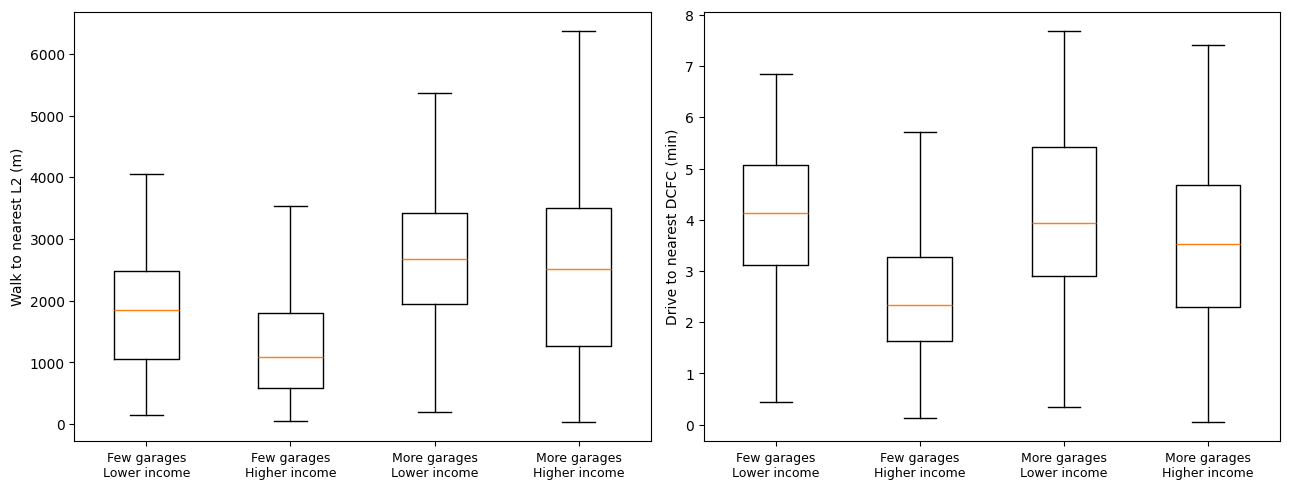

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
order = ["Few garages / Lower income", "Few garages / Higher income",
         "More garages / Lower income", "More garages / Higher income"]
d = bg.dropna(subset=["income_grp"])
for ax, col, label in zip(axes, ["walk_l2_m", "drive_dcfc_min"], ["Walk to nearest L2 (m)", "Drive to nearest DCFC (min)"]):
    ax.boxplot([d.loc[d.group == g, col] for g in order], showfliers=False)
    ax.set_xticklabels([g.replace(" / ", "\n") for g in order], fontsize=9)
    ax.set_ylabel(label)
plt.tight_layout()

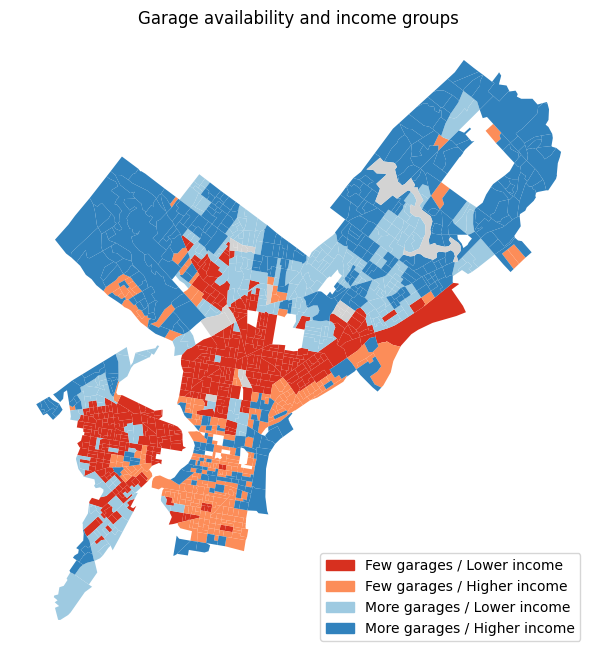

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = {"Few garages / Lower income": "#d7301f", "Few garages / Higher income": "#fc8d59",
          "More garages / Lower income": "#9ecae1", "More garages / Higher income": "#3182bd"}
for g, c in colors.items():
    bg[bg.group == g].plot(color=c, ax=ax, label=g)
bg[bg.income_grp.isna()].plot(color="lightgrey", ax=ax)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in colors.items()], loc="lower right")
ax.set_title("Garage availability and income groups"); ax.set_axis_off()